Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import datetime as dt
import matplotlib.pyplot as plt
from scipy.stats import norm

Setting Up Dates

In [2]:
# taking almost 16yrs of data 

startdate= ('2010-01-01') 
enddate= ('2026-10-17')

Download Close Prices

In [3]:
# Create an empty DataFrame to store the close prices

close_price= pd.DataFrame()

# Download the close prices for ticker in our case Nifty 50

data= yf.download('^NSEI', start= startdate, end= enddate)
close_price= data['Close']

print(close_price)

[*********************100%***********************]  1 of 1 completed

Ticker             ^NSEI
Date                    
2010-01-04   5232.200195
2010-01-05   5277.899902
2010-01-06   5281.799805
2010-01-07   5263.100098
2010-01-08   5244.750000
...                  ...
2026-10-12  22363.349609
2026-10-13  22721.949219
2026-10-14  22622.699219
2026-10-15  22997.349609
2026-10-16  23146.150391

[4124 rows x 1 columns]


Calculate daily log returns and drop any NAs

In [4]:
log_returns= np.log(close_price/close_price.shift(1)).dropna()
print(log_returns)

Ticker         ^NSEI
Date                
2010-01-05  0.008696
2010-01-06  0.000739
2010-01-07 -0.003547
2010-01-08 -0.003493
2010-01-11  0.000886
...              ...
2026-10-12 -0.007000
2026-10-13  0.015908
2026-10-14 -0.004378
2026-10-15  0.016425
2026-10-16  0.006450

[4123 rows x 1 columns]


Calculating the required Parameters from the above data 

In [5]:
spot_price= close_price.iloc[-1].item()                       # Spot price as on 2026-10-16 
strike_price= 23200                                           # Nearest strike price relative to current spot price   
risk_free_rate= np.log(1+.06)                                 # Continuously compounded risk-free rate (assuming 6% annual rate)
current_date = dt.date(2026,10,16)                            # Current valuation date 
maturity_date = dt.date(2026,10,27)                           # and contract maturity date, Expiry date for Nifty 50 contract 
time_to_maturity= ((maturity_date-current_date).days)/365     # Time to maturity in years (Actual/365 convention)
vol_yrly= np.std(log_returns)*np.sqrt(252)                    # Annualized historical volatility from daily log returns (252 trading days)
dividend_yield= np.log(1+0.013)                               # Continuously compounded dividend yield (assuming 1.3% annual yield)

Defining the parameters according to  Formulas

In [6]:
S = spot_price
K = strike_price
rf = risk_free_rate
sigma= vol_yrly
T= time_to_maturity
q = dividend_yield

<br>

<span style="font-size: 30px;">**1. Black Scholes Model for Option Pricing:**</span>


<br>



D1 Calculation Formula:

$$d1 = \frac{\ln\left(\frac{S}{K}\right) + \left(r - q + \frac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}}$$


In [7]:

D1= (np.log(S/K)+(rf-q + 1/2*sigma**2)*T)/(sigma* np.sqrt(T))
print(D1)

-0.019105238946980817


D2 Calcualtion Formula:
$$d2= d1 - \sigma\sqrt{T}$$

In [8]:
D2= D1 - sigma*np.sqrt(T)
print (D2)

-0.04773915971457273


Calculate Call Option Price:
$$C = S * e^{-qT}N(d1) - K * e^{-rT} * N(d2)$$

In [9]:
C = S*np.exp(-q*T)*norm.cdf(D1) - K*np.exp(-rf*T) * norm.cdf(D2)



Calculate Put Option Price:
$$P = K * e^{-rT} * N(-d2) - S * e^{qT}N(-d1)$$

In [10]:
P = K*np.exp(-rf*T) * norm.cdf(-D2) - S*np.exp(-q*T)*norm.cdf(-D1)


In [11]:
print("Call Option Price:",C)
print("Put Option Price:", P)

Call Option Price: 253.4907294060813
Put Option Price: 275.6437724370662


<br>

<span style="font-size: 30px;">**2. Monte Carlo simulations for Option Pricing:**</span>

<br>

Calculating Simmulated Stock Prices:
$$
S_T = S_0 e^{\left(r - q - \frac{1}{2}\sigma^2\right)T + \sigma \sqrt{T} Z}
$$

Running Monte Carlo Simulation to calculate simulated prices

In [12]:
sim = 10000000         # No. of simulation

z_score_random= np.random.standard_normal(sim)   # Standard normal Z-score
simulated_prices = S * np.exp((rf - q - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * z_score_random)     # Calculating simlated prices

Calculating Call an Put Payoff from the Simulated prices 

In [13]:
call_payoff= np.maximum(simulated_prices - K,0)
put_payoff= np.maximum(K - simulated_prices,0)
print(call_payoff)
print(put_payoff)

[  0.           0.         595.05226375 ... 782.36577425   0.
   0.        ]
[  13.5619806   510.40793776    0.         ...    0.         1470.80607317
 1174.49442673]


Taking the discounted Call and Put prices

In [14]:
discounted_call_price= np.mean(call_payoff)*np.exp(-rf*T)     
discounted_put_price= np.mean(put_payoff)*np.exp(-rf*T)

print("Call Option Price:",discounted_call_price)
print("Put Option Price:",discounted_put_price)

Call Option Price: 253.2150750929324
Put Option Price: 275.7808584806377


Calculating standard error for Call and Put

In [15]:
std_error_call= np.std(call_payoff)/np.sqrt(sim) 
std_error_put= np.std(put_payoff)/np.sqrt(sim)

print('Std Error Call',std_error_call)
print('Std Error Put',std_error_put)

Std Error Call 0.12218376691847255
Std Error Put 0.12290165012967384


Ploting the Simulated Prices to check the Distribution

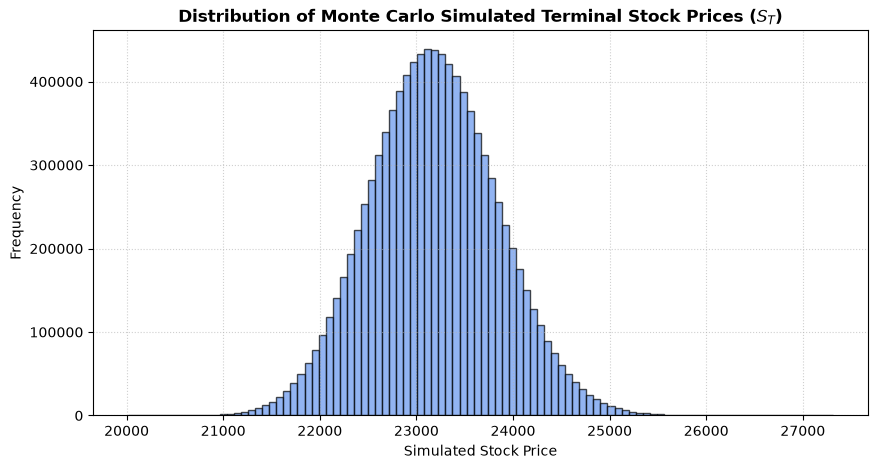

In [16]:
plt.figure(figsize=(10, 5))
plt.hist(
    simulated_prices,
    bins=100,
    edgecolor="black",
    alpha=0.7,
    color="cornflowerblue",
)

plt.title(
    "Distribution of Monte Carlo Simulated Terminal Stock Prices ($S_T$)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Simulated Stock Price", fontsize=10)
plt.ylabel("Frequency", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()